# Compare the effect of measured surface factors at one shoulder under a finite record.

Run in a Python environment with OneSimulation 0.2.0, NumPy, SciPy and Matplotlib. Change the input data and rerun to compare with the saved reference output.

counted cycle equivalents 4.0
surface factor 0.70: damage per record = 9.8463e-07
surface factor 0.90: damage per record = 2.8025e-07


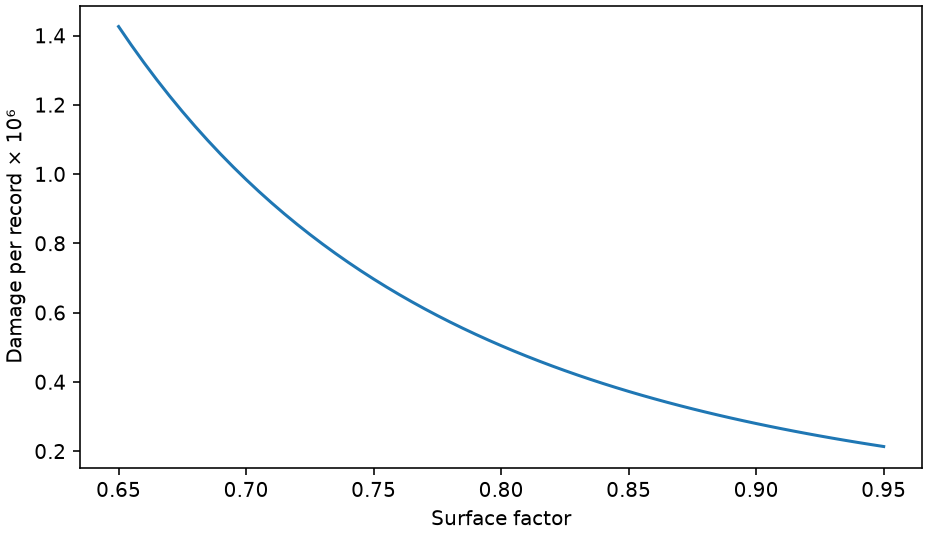

In [1]:
"""Compare the effect of measured surface factors at one shoulder under a finite record."""
import numpy as np
import matplotlib.pyplot as plt
from onesim.physics.solid_mechanics.fatigue.models.cycles.cycle_counting import fatigue_cycles

nominal = np.array([0,110,-40,85,-65,130,-55,80,0.0])  # MPa
cycles = list(fatigue_cycles(stress=nominal))
surface = np.linspace(0.65, 0.95, 61)
kt, notch_sensitivity, ultimate = 1.65, 0.8, 650.0  # ultimate in MPa
kf = 1+notch_sensitivity*(kt-1)
# Illustrative calibrated finite-life power law. Reference life: one million cycles.
def block_damage(ka):
    strength = 280*ka*0.88  # MPa at reference life, after size correction
    damage = 0.0
    for cycle in cycles:
        mean = kt*max(cycle.mean_stress, 0)
        alternating = kf*cycle.stress_amplitude/(1-mean/ultimate)
        damage += cycle.count/1e6*(alternating/strength)**5
    return damage

damage = np.array([block_damage(value) for value in surface])
print("counted cycle equivalents", sum(cycle.count for cycle in cycles))
for ka in [0.70, 0.90]:
    print(f"surface factor {ka:.2f}: damage per record = {block_damage(ka):.4e}")
fig, ax = plt.subplots(figsize=(6.4,3.7), layout="constrained")
ax.plot(surface, 1e6*damage)
ax.set(xlabel="Surface factor", ylabel="Damage per record × 10⁶")
plt.show()
